# Importing Modules


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



# Loading DataSet


In [3]:
df = pd.read_csv("../data/raw/car_details.xls")

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [5]:
df.shape


(4340, 8)

In [6]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [8]:
df.dtypes

name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

# EDA - Exploratory Data Analysis


### **1. Distribution of Cars by Fuel Type**

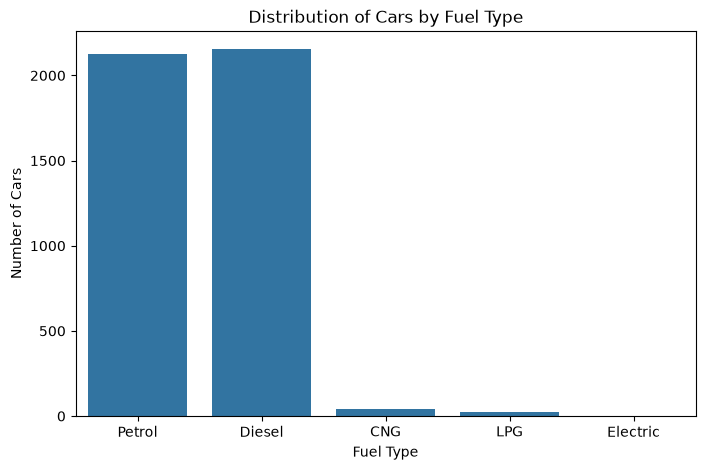

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(x=df['fuel'])

plt.title("Distribution of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

### **2. Number of Cars by Manufacturing Year**


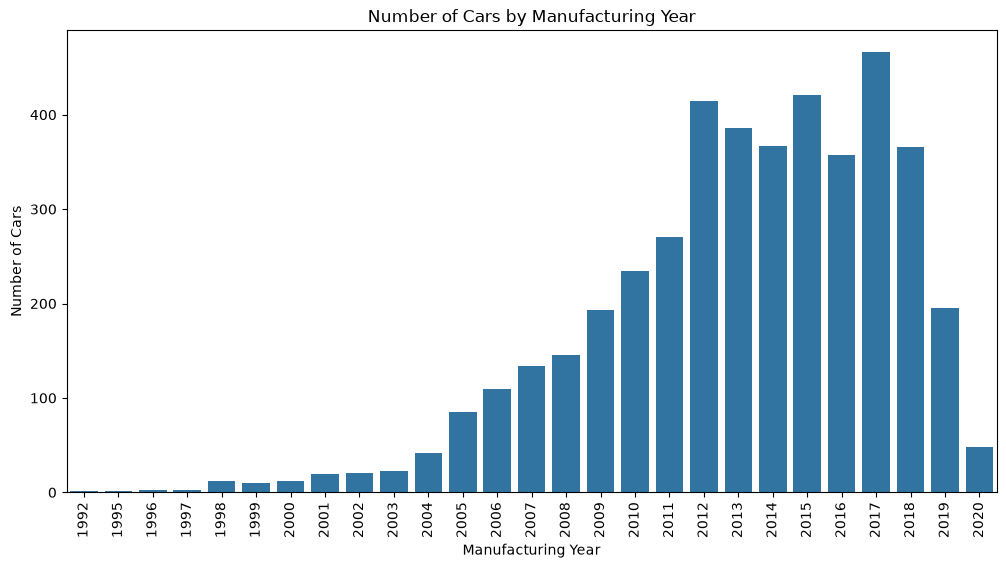

In [10]:
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='year')

plt.title("Number of Cars by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Number of Cars")

plt.xticks(rotation=90)
plt.show()

### **3. Relationship between Year and Selling Price**


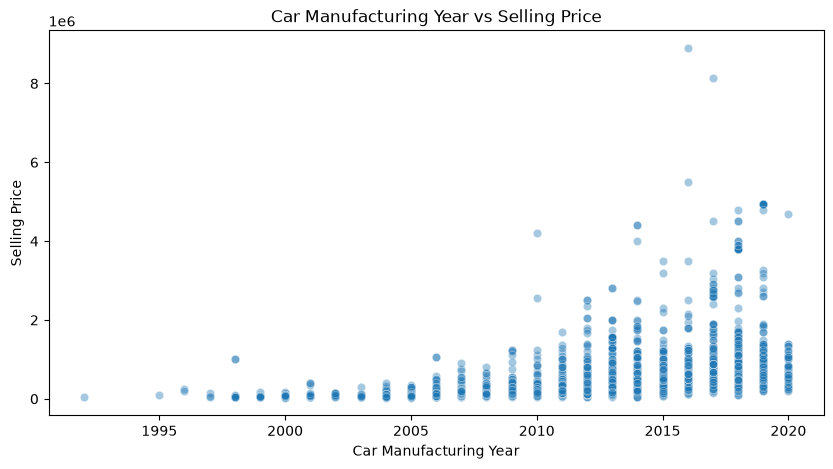

In [11]:
plt.figure(figsize=(10, 5))


sns.scatterplot(
    data=df,
    x='year',
    y='selling_price',
    alpha=0.4
)

plt.title("Car Manufacturing Year vs Selling Price")
plt.xlabel("Car Manufacturing Year")
plt.ylabel("Selling Price")

plt.show()


### **4. Average Selling Price per year**

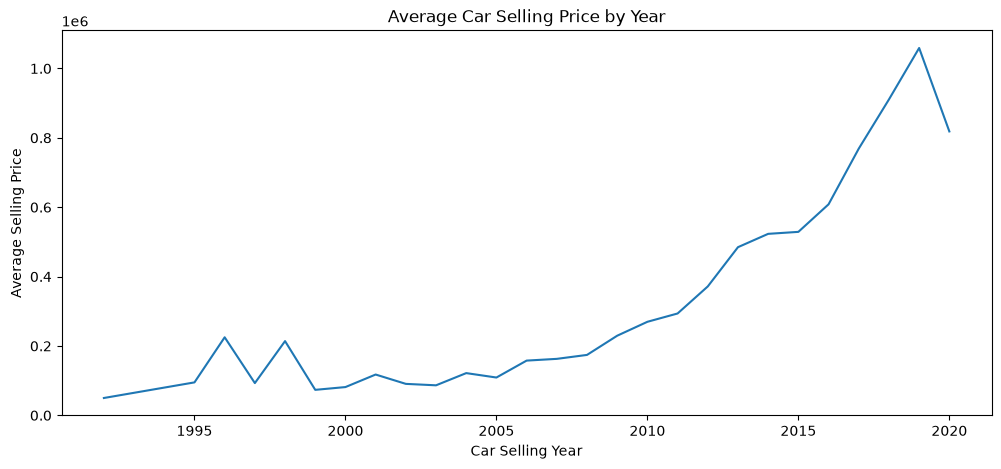

In [12]:
yearly_price=df.groupby('year')['selling_price'].mean()
yearly_price

plt.figure(figsize=(12, 5))
sns.lineplot(x=yearly_price.index, y=yearly_price.values)
plt.title("Average Car Selling Price by Year")
plt.xlabel("Car Selling Year")
plt.ylabel("Average Selling Price")
plt.show()



### **5. Distribution of Used Car Selling Prices**

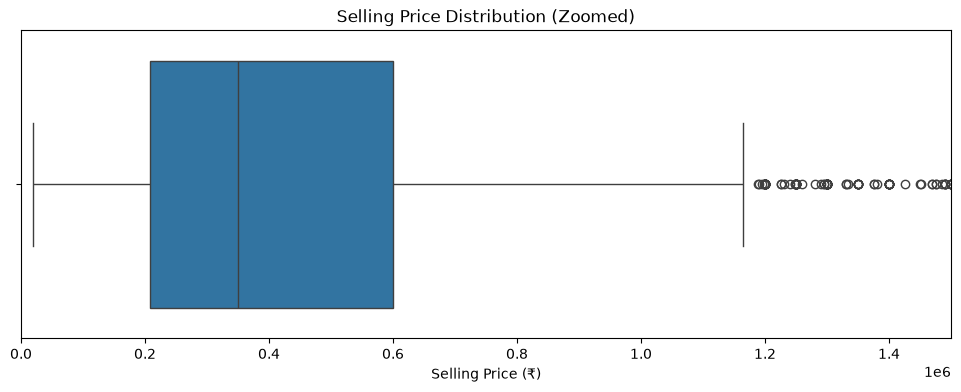

In [13]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=df['selling_price'])

plt.xlim(0, 1500000)

plt.title("Selling Price Distribution (Zoomed)")
plt.xlabel("Selling Price (₹)")

plt.show()

##### -  Values of Quantile

In [14]:
Q1=df['selling_price'].quantile(0.25)
Q2=df['selling_price'].quantile(0.50)
Q3=df['selling_price'].quantile(0.75)

print("Q1:", Q1)
print("Median:", Q2)
print("Q3:", Q3)

Q1: 208749.75
Median: 350000.0
Q3: 600000.0


##### - Upper and Lower Limit

In [15]:
IQR=Q3-Q1
upperLimit = Q3+1.5*IQR
print("Upper limit:", upperLimit)

lowerLimit= Q1-1.5*IQR
print("Lower limit:", lowerLimit)




Upper limit: 1186875.375
Lower limit: -378125.625


### **6. Relationship between KM Driven and Selling Price**

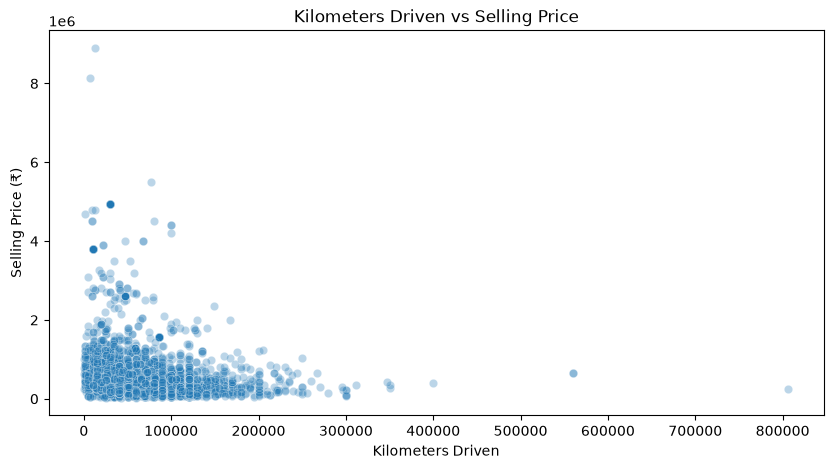

In [16]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='km_driven',
    y='selling_price',
    alpha=0.3
)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (₹)")

plt.show()

##### - Pearson Correlation Coefficient

In [17]:
correlation = df['km_driven'].corr(df['selling_price'])
print(correlation)

-0.19228863054511444


### **7. HeatMap Correlation**

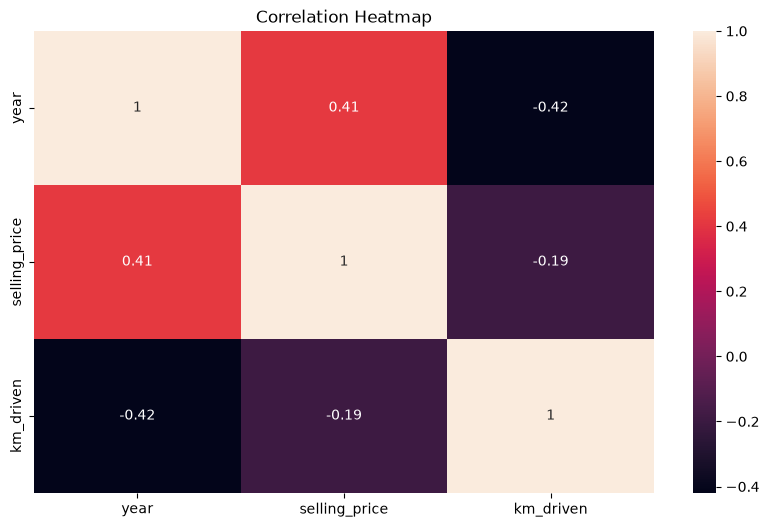

In [18]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,6))

sns.heatmap(corr, annot=True)


plt.title("Correlation Heatmap")

plt.show()

### **8. Selling Price by Fuel Type**

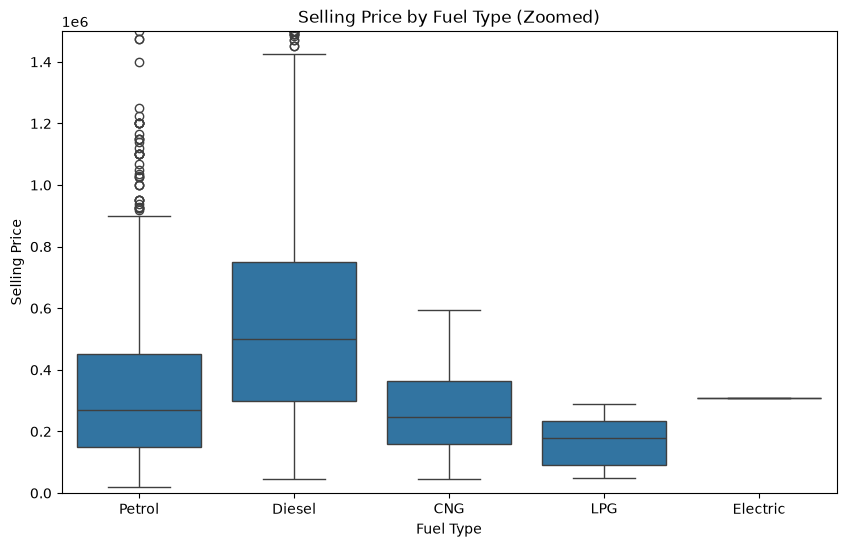

In [19]:
plt.figure(figsize=(10,6))

sns.boxplot(x=df['fuel'], y=df['selling_price'])
plt.title("Selling Price by Fuel Type (Zoomed)")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.ylim(0, 1500000)

plt.show()

### **9. Selling Price by Transmission**

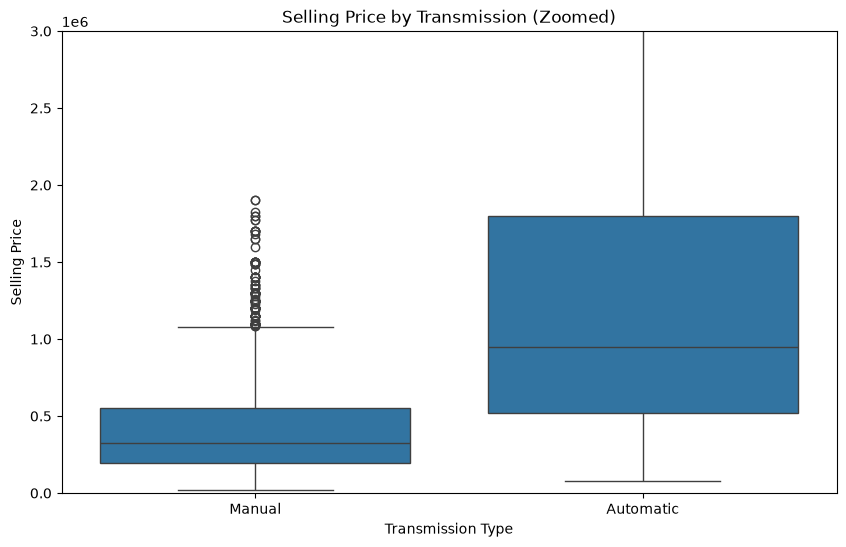

In [20]:
plt.figure(figsize=(10,6))

sns.boxplot(x=df['transmission'], y=df['selling_price'])
plt.title("Selling Price by Transmission (Zoomed)")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price")
plt.ylim(0, 3000000)

plt.show()

##### - Median per Transmission

In [21]:
df.groupby('transmission')['selling_price'].median().sort_values()#

transmission
Manual       325000.0
Automatic    950000.0
Name: selling_price, dtype: float64

### **10. Selling Price by Seller Type**

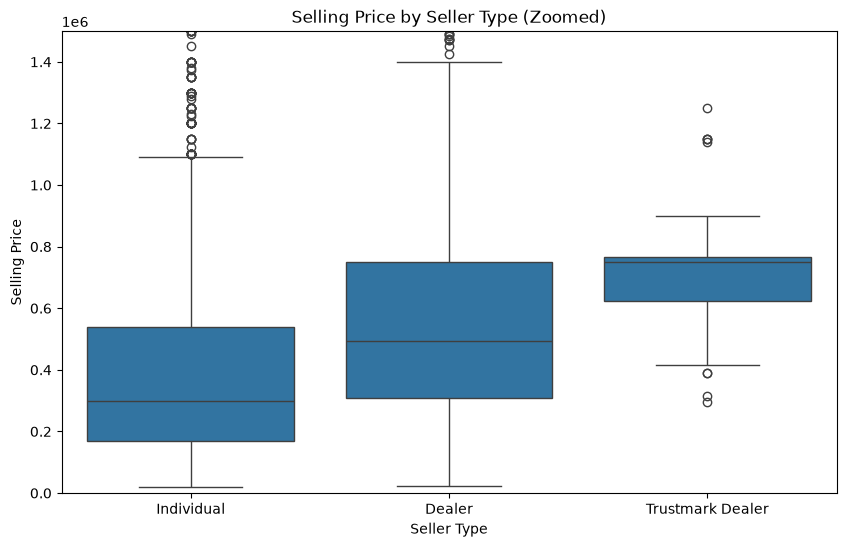

In [22]:
plt.figure(figsize=(10,6))

sns.boxplot(x=df['seller_type'], y=df['selling_price'])

plt.title("Selling Price by Seller Type (Zoomed)")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price")
plt.ylim(0,1500000)
plt.show()

##### - Median per Seller Type

In [23]:
df.groupby('seller_type')['selling_price'].median().sort_values()

seller_type
Individual          300000.0
Dealer              495000.0
Trustmark Dealer    750000.0
Name: selling_price, dtype: float64

### **11. Selling Price by Number of Previous Owners**

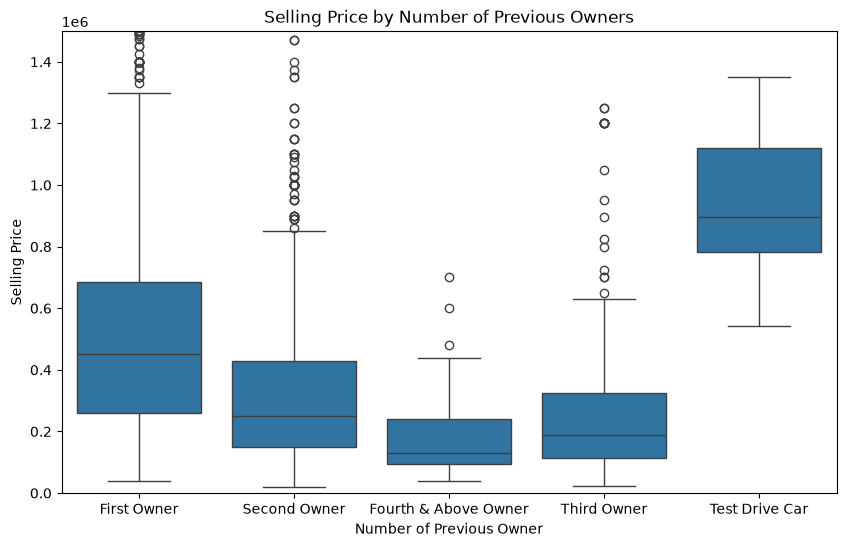

In [24]:
plt.figure(figsize=(10,6))
sns.boxplot(x=df['owner'],y=df['selling_price'])

plt.title("Selling Price by Number of Previous Owners")
plt.xlabel("Number of Previous Owner")
plt.ylabel("Selling Price")

plt.ylim(0,1500000)
plt.show()

##### - Median per Number of Owners

In [25]:
df.groupby('owner')['selling_price'].median().sort_values()

owner
Fourth & Above Owner    130000.0
Third Owner             190000.0
Second Owner            250499.5
First Owner             450000.0
Test Drive Car          894999.0
Name: selling_price, dtype: float64

### **12.Car Age vs Selling Price**

In [26]:
current_year=2026
df['car_age']=current_year-df['year']

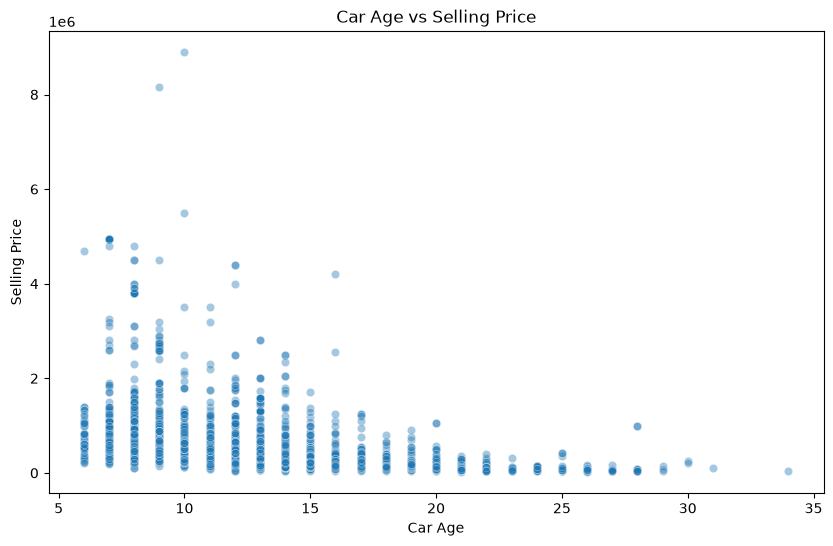

In [27]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=df['car_age'],y=df['selling_price'], alpha=0.4)

plt.xlabel("Car Age")
plt.ylabel("Selling Price")
plt.title("Car Age vs Selling Price")
plt.show()

### **13. Distribution of Selling Price**

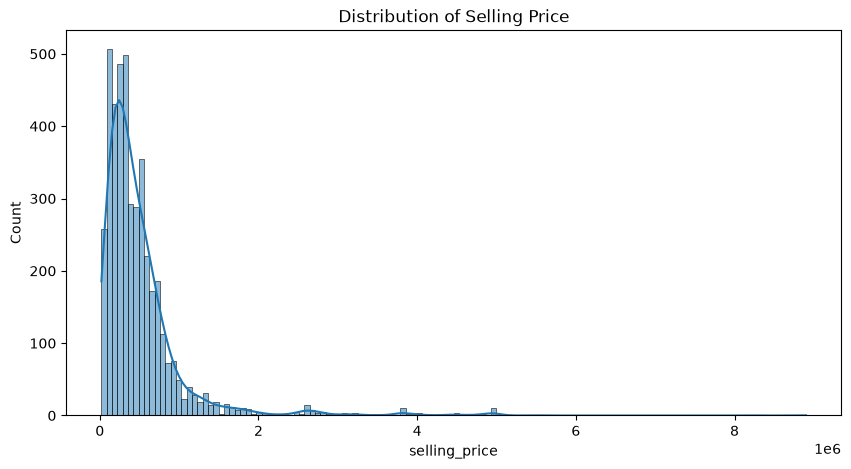

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(df['selling_price'], kde=True)

plt.title("Distribution of Selling Price")
plt.show()

### **14. Other EDA Checks**

In [29]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
car_age          0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(763)

In [31]:
df.describe()

,year,selling_price,km_driven,car_age
count,4340.000000,4.340000e+03,4340.000000,4340.000000
mean,2013.090783,5.041273e+05,66215.777419,12.909217
std,4.215344,5.785487e+05,46644.102194,4.215344
min,1992.000000,2.000000e+04,1.000000,6.000000
25%,2011.000000,2.087498e+05,35000.000000,10.000000
50%,2014.000000,3.500000e+05,60000.000000,12.000000
75%,2016.000000,6.000000e+05,90000.000000,15.000000
max,2020.000000,8.900000e+06,806599.000000,34.000000
